# Riyadh Hotels 2026 — Exploratory Data Analysis

## Introduction
**What is the dataset about?**
The dataset contains hotel offers in Riyadh (2026) collected from two sources, Booking.com and TripAdvisor. Each row is an offer for one hotel on specific check-in / check-out dates, with the hotel location, rating, number of reviews and the total stay price. These are displayed prices, not confirmed bookings.

**Main questions we will explore**
1. How are hotel prices per night distributed, and what is a typical price?
2. Are rating and number of reviews related to the price?
3. Does the length of stay or the check-in date affect the price?
4. How do Booking.com and TripAdvisor differ in price and rating?
5. Where are the hotels located in Riyadh?

**Insights we expect to uncover**
- Prices are right-skewed: most hotels are moderately priced and a few luxury hotels are very expensive.
- Higher-rated hotels tend to be more expensive.
- Booking.com prices are higher than TripAdvisor prices.
- Longer stays have a slightly lower price per night.
- Prices may change on busy dates such as holidays.

In [1]:
# Data Handling
import pandas as pd
import numpy as np

#  Visualization
import seaborn as sns
import matplotlib.pyplot as plt
from kagglehub import KaggleDatasetAdapter

# Load Dataset

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mohammedalsubaie/riyadh-hotels-2026")

print("Path to dataset files:", path)

100%|██████████| 167k/167k [00:00<00:00, 84.3MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/mohammedalsubaie/riyadh-hotels-2026/versions/1


In [3]:
import os

path = kagglehub.dataset_download(
    "mohammedalsubaie/riyadh-hotels-2026"
)

file_path = os.path.join(path, "Riyadh_hotels.parquet")

df = pd.read_parquet(file_path)



Using Colab cache for faster access to the 'riyadh-hotels-2026' dataset.


# Data Understanding (Initial Exploration)
we take a first look at the dataset to understand its structure, columns, data types, and basic statistics. This helps us identify potential issues and get familiar with the data before cleaning and deeper analysis.

In [4]:
# Display the first 5 rows of the dataset
# This helps us understand the structure of the data, column names, and initial values.

df.head()

,hotel_id,hotel_name,city,latitude,longitude,rating,reviews_count,price,checkin_date,checkout_date,Source
0,23735764,Movenpick Hotel And Residences Riyadh,Riyadh,24.764044,46.653236,4.9,777.0,197.0,2026-05-03,2026-05-05,TripAdvisor
1,23569851,Fairmont Ramla Riyadh,Riyadh,24.809305,46.624146,4.8,202.0,305.0,2026-05-03,2026-05-05,TripAdvisor
2,24143026,Joudyan Hotel,Riyadh,24.699400,46.682755,4.9,603.0,86.0,2026-05-03,2026-05-05,TripAdvisor
3,15215188,Fairmont Riyadh,Riyadh,24.808397,46.718050,4.7,240.0,270.0,2026-05-03,2026-05-05,TripAdvisor
4,3514706,ibis Riyadh Olaya Street,Riyadh,24.712132,46.676740,3.8,460.0,59.0,2026-05-03,2026-05-05,TripAdvisor


In [5]:
# Display the last 5 rows of the dataset
# This helps us check if there are any unusual values or issues at the end of the file.
df.tail()

,hotel_id,hotel_name,city,latitude,longitude,rating,reviews_count,price,checkin_date,checkout_date,Source
9844,14573150,فخامة المكان للشقق المخدومة2,Riyadh,24.762659,46.834519,NaN,NaN,320.4000,2026-05-05,2026-05-06,Booking.com
9845,15666518,غرفتين نوم مع صاله دخول ذاتي,Riyadh,24.775367,46.625174,NaN,1.0,443.7000,2026-05-05,2026-05-06,Booking.com
9846,13756026,شقة فاخرة غرفتين نوم وصالة بمطبخ مستقل 013l,Riyadh,24.774674,46.623603,NaN,2.0,809.1000,2026-05-05,2026-05-06,Booking.com
9847,9381914,شقة فاخرة مقابل البوليفارد,Riyadh,24.776852,46.615817,8.9,77.0,540.0000,2026-05-05,2026-05-06,Booking.com
9848,9542538,راحة Comfort,Riyadh,24.813891,46.736036,8.6,75.0,554.4001,2026-05-05,2026-05-06,Booking.com


In [6]:
# Display column names as a list
df.columns.tolist()

['hotel_id',
 'hotel_name',
 'city',
 'latitude',
 'longitude',
 'rating',
 'reviews_count',
 'price',
 'checkin_date',
 'checkout_date',
 'Source']

In [7]:
# Check the shape of the dataset (rows, columns)
# This tells us how many samples and features we have.
df.shape

(9849, 11)

In [8]:
# Get the total number of elements in the dataset (rows × columns)
# This is less commonly used but gives an idea of the dataset's overall size.
df.size

108339

In [9]:
# Display basic information about the dataset
# This helps us see the number of rows, columns, data types, and if there are missing values.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9849 entries, 0 to 9848
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   hotel_id       9849 non-null   int64  
 1   hotel_name     9849 non-null   object 
 2   city           9249 non-null   object 
 3   latitude       9743 non-null   float64
 4   longitude      9743 non-null   float64
 5   rating         8666 non-null   float64
 6   reviews_count  9173 non-null   float64
 7   price          9119 non-null   float64
 8   checkin_date   9849 non-null   object 
 9   checkout_date  9849 non-null   object 
 10  Source         9849 non-null   object 
dtypes: float64(5), int64(1), object(5)
memory usage: 846.5+ KB


In [10]:
#convert type date column to datetime
df["checkin_date"] = pd.to_datetime(
    df["checkin_date"], errors="coerce"
)

df["checkout_date"] = pd.to_datetime(
    df["checkout_date"], errors="coerce"
)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9849 entries, 0 to 9848
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   hotel_id       9849 non-null   int64         
 1   hotel_name     9849 non-null   object        
 2   city           9249 non-null   object        
 3   latitude       9743 non-null   float64       
 4   longitude      9743 non-null   float64       
 5   rating         8666 non-null   float64       
 6   reviews_count  9173 non-null   float64       
 7   price          9119 non-null   float64       
 8   checkin_date   9849 non-null   datetime64[ns]
 9   checkout_date  9849 non-null   datetime64[ns]
 10  Source         9849 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(1), object(3)
memory usage: 846.5+ KB


In [11]:
# Summary statistics for numerical columns
# This helps us understand the distribution, central tendency, and detect possible outliers.
df.describe()

,hotel_id,latitude,longitude,rating,reviews_count,price,checkin_date,checkout_date
count,9.849000e+03,9743.000000,9743.000000,8666.000000,9173.000000,9119.000000,9849,9849
mean,1.293544e+07,24.752135,46.682500,6.320932,276.222501,2403.110517,2026-05-13 06:14:43.825769216,2026-05-18 09:15:26.591532288
min,2.319800e+04,20.433859,34.513622,0.000000,0.000000,17.000000,2026-04-27 00:00:00,2026-04-29 00:00:00
25%,9.083803e+06,24.697400,46.628326,4.325000,3.000000,392.281800,2026-05-05 00:00:00,2026-05-10 00:00:00
50%,1.294656e+07,24.774778,46.684670,7.700000,27.000000,1413.000100,2026-05-12 00:00:00,2026-05-19 00:00:00
75%,1.542651e+07,24.805456,46.735570,8.600000,227.000000,3060.900050,2026-05-21 00:00:00,2026-05-27 00:00:00
max,3.434388e+07,28.534224,55.274418,10.000000,7746.000000,301234.000000,2026-05-30 00:00:00,2026-05-31 00:00:00
std,7.498171e+06,0.135187,0.258501,3.141342,617.161417,4609.451069,NaN,NaN


**Observations:** `rating` has a minimum of 0 while the 25th percentile is about 4.3, so zeros need checking. `price` has a very large maximum (301,234) compared to the median, which suggests extreme values. The latitude and longitude ranges also look wider than the city of Riyadh.

# Data Cleaning and Preprocessing
we check the dataset for missing values, duplicates, inconsistent data, and prepare the features for analysis.
This step ensures the data is clean, reliable, and ready for deeper exploration and modeling.

### Duplicates

In [12]:
df.duplicated().sum() # we have duplicated

np.int64(716)

In [13]:
# Remove duplicate rows
df = df.drop_duplicates()

In [14]:
df.shape

(9133, 11)

### Missing values

In [15]:
df.isnull().sum()

,0
hotel_id,0
hotel_name,0
city,600
latitude,106
longitude,106
rating,1117
reviews_count,647
price,717
checkin_date,0
checkout_date,0


In [16]:
#Percentage Missing
(df.isnull().sum() / len(df)) * 100
#notice we have a missing data >5%

,0
hotel_id,0.000000
hotel_name,0.000000
city,6.569583
latitude,1.160626
longitude,1.160626
rating,12.230373
reviews_count,7.084200
price,7.850651
checkin_date,0.000000
checkout_date,0.000000


**Observations:** `city`, `rating`, `reviews_count` and `price` each have more than 5% missing values, so they are handled one by one below.

In [17]:
# Fill missing city values
#Since all the data in the city column is for the city of Riyadh, the missing data will be filled in with the city of Riyadh.
df["city"] = df["city"].fillna("Riyadh")

In [18]:
df['city'].isnull().sum()

np.int64(0)

### Coordinates

In [19]:
# Remove rows with missing latitude or longitude (about 1% of the data),
# because valid coordinates are needed for the location analysis.
df = df.dropna(subset=["latitude", "longitude"])

In [20]:
df[["latitude", "longitude"]].isnull().sum()

,0
latitude,0
longitude,0


### Rating and reviews_count

In [21]:
# Check missing and zero values in rating and reviews_count
print("Missing ratings:", df["rating"].isna().sum())
print("Zero ratings:", (df["rating"] == 0).sum())

print("Missing reviews:", df["reviews_count"].isna().sum())
print("Zero reviews:", (df["reviews_count"] == 0).sum())

Missing ratings: 1117
Zero ratings: 1041
Missing reviews: 647
Zero reviews: 1041


In [22]:
# Check the rating distribution, including zero
df["rating"].value_counts().sort_index()

,count
rating,
0.0,1041
1.0,83
1.4,9
1.5,10
1.8,5
...,...
9.6,90
9.7,92
9.8,81


In [23]:
# Replace zero ratings with NaN because rating platforms start at 1,
# and hotels with zero ratings have zero reviews, indicating no actual rating.
df["rating"] = df["rating"].replace(0, np.nan)

In [24]:
# Verify missing and zero values after cleaning
print("Missing ratings:", df["rating"].isna().sum())
print("Zero ratings:", (df["rating"] == 0).sum())

print("Missing reviews:", df["reviews_count"].isna().sum())
print("Zero reviews:", (df["reviews_count"] == 0).sum())

Missing ratings: 2158
Zero ratings: 0
Missing reviews: 647
Zero reviews: 1041


Missing values in `rating` and `reviews_count` were retained because the actual values are unknown. Imputing them without sufficient evidence could affect the accuracy of the analysis. Zero review counts were preserved because they may represent hotels with no reviews, while zero ratings were treated as missing because the rating scale starts at 1.

### Price

In [25]:
# Check missing values and basic statistics for hotel prices
print("Missing prices:", df["price"].isna().sum())
print(df.groupby("Source")["price"].describe())

Missing prices: 675
              count         mean          std     min    25%     50%     75%  \
Source                                                                         
Booking.com  6645.0  3062.633680  5175.238717  92.115  990.0  2000.0  3709.8   
TripAdvisor  1707.0   112.736965   130.090033  17.000   59.5    77.0   105.0   

                  max  
Source                 
Booking.com  301234.0  
TripAdvisor    1385.0  


In [26]:
'''The currency is not standardized, so we will standardize it by converting dollars to riyals.
 Note that all dollar exchange rates are from TripAdvisor.'''

# Rename the original price column
df = df.rename(columns={"price": "price_SAR"})

# Convert TripAdvisor prices from USD to SAR
df.loc[df["Source"] == "TripAdvisor", "price_SAR"] = (
    df.loc[df["Source"] == "TripAdvisor", "price_SAR"] * 3.75
)

In [27]:
df.head()

,hotel_id,hotel_name,city,latitude,longitude,rating,reviews_count,price_SAR,checkin_date,checkout_date,Source
0,23735764,Movenpick Hotel And Residences Riyadh,Riyadh,24.764044,46.653236,4.9,777.0,738.75,2026-05-03,2026-05-05,TripAdvisor
1,23569851,Fairmont Ramla Riyadh,Riyadh,24.809305,46.624146,4.8,202.0,1143.75,2026-05-03,2026-05-05,TripAdvisor
2,24143026,Joudyan Hotel,Riyadh,24.699400,46.682755,4.9,603.0,322.50,2026-05-03,2026-05-05,TripAdvisor
3,15215188,Fairmont Riyadh,Riyadh,24.808397,46.718050,4.7,240.0,1012.50,2026-05-03,2026-05-05,TripAdvisor
4,3514706,ibis Riyadh Olaya Street,Riyadh,24.712132,46.676740,3.8,460.0,221.25,2026-05-03,2026-05-05,TripAdvisor


In [28]:
df.groupby("Source")["price_SAR"].describe()

,count,mean,std,min,25%,50%,75%,max
Source,,,,,,,,
Booking.com,6645.0,3062.63368,5175.238717,92.115,990.000,2000.00,3709.80,301234.00
TripAdvisor,1707.0,422.76362,487.837624,63.750,223.125,288.75,393.75,5193.75


In [29]:
df.groupby("Source")["price_SAR"].apply(
    lambda x: x.isnull().sum() / len(x) * 100
)
# we notice all missing in TripAdvisor

,price_SAR
Source,
Booking.com,0.000000
TripAdvisor,28.337531


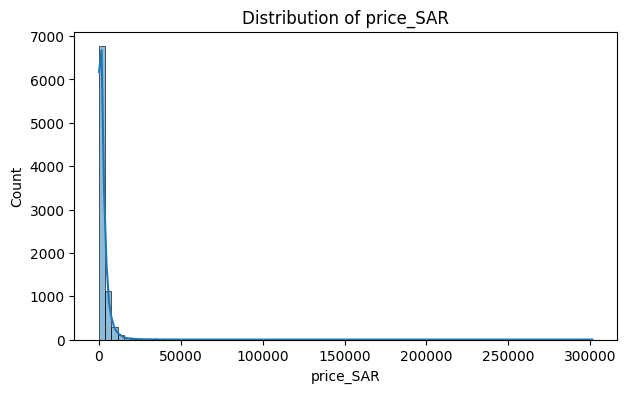

In [30]:
plt.figure(figsize=(7,4))
sns.histplot(data=df, x="price_SAR", bins=80, kde=True)

plt.title("Distribution of price_SAR")
plt.xlabel("price_SAR")
plt.ylabel("Count")
plt.show()

 **Price** **Insights**:
- Booking.com prices are higher than TripAdvisor prices on average, even after converting USD to SAR.
- Price data is right-skewed, with a few extremely high values that may be outliers.
- TripAdvisor has a relatively high percentage of missing prices, which may affect the analysis.
- Prices represent the total stay cost, so the number of nights should be considered for a fair comparison.

### Stay duration and price per night

In [31]:
# Create a new column for the stay duration
# Calculate the number of nights for each hotel stay to compare prices fairly across different stay durations.
df["stay_duration"] = (
    df["checkout_date"] - df["checkin_date"]
).dt.days

In [32]:
# Calculate the price per night for each hotel stay
df["price_per_night"] = df["price_SAR"] / df["stay_duration"]

### Outliers in price

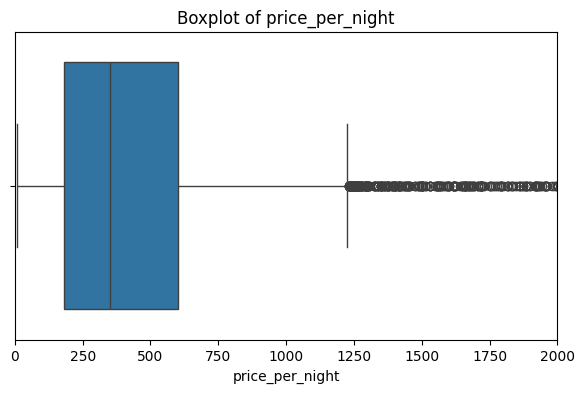

In [67]:
plt.figure(figsize=(7,4))
sns.boxplot(x=df["price_per_night"])
plt.xlim(0, 2000)
plt.title("Boxplot of price_per_night")
plt.xlabel("price_per_night")
plt.show()

In [34]:
# Calculate IQR
Q1 = df["price_per_night"].quantile(0.25)
Q3 = df["price_per_night"].quantile(0.75)

IQR = Q3 - Q1

# Define outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

lower_bound, upper_bound

(np.float64(-381.0), np.float64(1235.0))

In [35]:
#check nigative or zero value in price
(df["price_per_night"] <= 0).sum()

np.int64(0)

**Decision:** the IQR bounds flag many high prices as outliers, but the very high values represent real luxury hotels, so we kept them. We deal with their effect by using the median, Spearman correlation and a logarithmic scale instead of deleting them. All prices per night are above zero.

### Missing prices

In [36]:
df.isnull().sum()

,0
hotel_id,0
hotel_name,0
city,0
latitude,0
longitude,0
rating,2158
reviews_count,647
price_SAR,675
checkin_date,0
checkout_date,0


In [37]:
# Fill missing prices using the median of each source
df["price_SAR"] = df["price_SAR"].fillna(
    df.groupby("Source")["price_SAR"].transform("median")
)

In [38]:
# Recalculate price per night
df["price_per_night"] = (
    df["price_SAR"] / df["stay_duration"]
)

In [39]:
# Check missing values after imputation
df[["price_SAR", "price_per_night"]].isnull().sum()

,0
price_SAR,0
price_per_night,0


In [40]:
df[["price_SAR", "price_per_night"]].describe()

,price_SAR,price_per_night
count,9027.000000,9027.000000
mean,2356.016900,462.560924
std,4599.339562,718.594762
min,63.750000,9.000000
25%,360.000000,180.000000
50%,1262.655000,350.000000
75%,2978.625000,600.000000
max,301234.000000,50205.666667


**Note:** the missing prices were all in TripAdvisor and were filled with the median price of their source.

# Exploratory Data Analysis (EDA)

**Note about the data:** the dataset has many rows for the same hotel on different dates, so the number of rows is larger than the number of unique hotels.

In [41]:
print(df["hotel_id"].nunique())

2728


**Insight:** there are 2,728 unique hotels but 9,027 offers, so each hotel appears several times with different dates and prices. We therefore describe the rows as *offers* and not as hotels.

**Univariate** **Analysis**

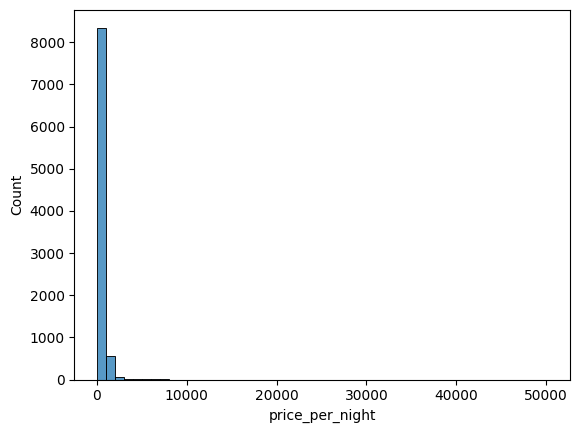

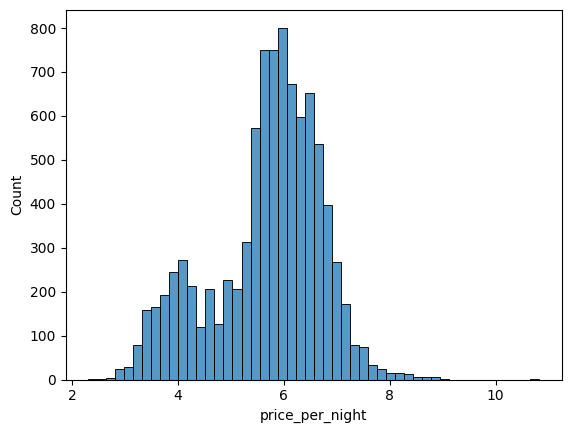

In [42]:
sns.histplot(df["price_per_night"], bins=50)
plt.show()

# log1p compresses the large values and clarifies the distribution
sns.histplot(np.log1p(df["price_per_night"]), bins=50)
plt.show()

Insight: Price-Per-Night Distribution

When plotting the price-per-night distribution in its original form, most hotels were clustered on the far left, creating a very long tail to the right, as some luxury hotels reach prices in the hundreds of thousands. This indicates that the distribution is highly right-skewed, further confirmed by the fact that the average (2,403) is significantly larger than the median (1,413).

Therefore, we used the np.log1p transformation to compress the large values ​​and clarify the distribution. After the transformation, the distribution became more symmetrical, clearly showing that most hotels fall within a mid-range price range, while luxury hotels are few and represent the tail of the distribution.

Conclusion: Hotel prices in Riyadh are not evenly distributed; most are moderately priced, and very few are high-priced. Therefore, we rely on the median rather than the average to describe the common price, and we use the logarithmic scale in the graphs and comparisons.

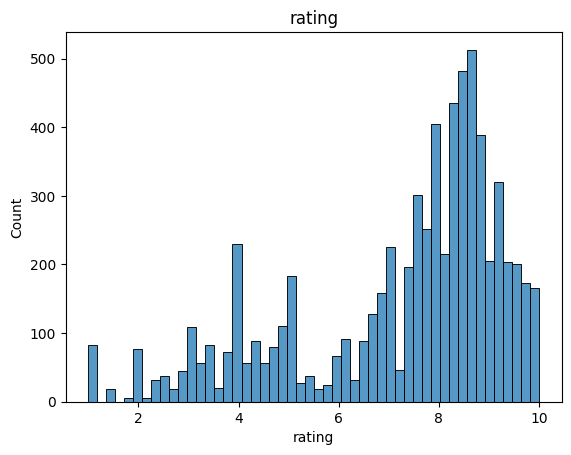

In [43]:
sns.histplot(df["rating"], bins=50)
plt.title("rating")
plt.show()

**Insight: Rating.** Most ratings are between 7 and 10. Note that the rating scale is not the same in both sources (TripAdvisor ratings look like they are out of 5, Booking.com out of 10, see the average rating by source below), so the histogram combines two scales.

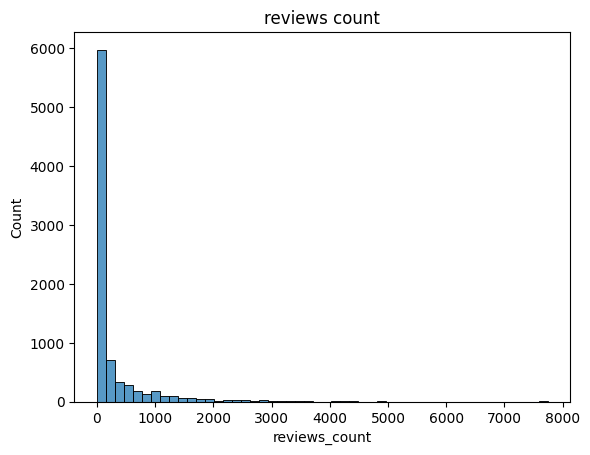

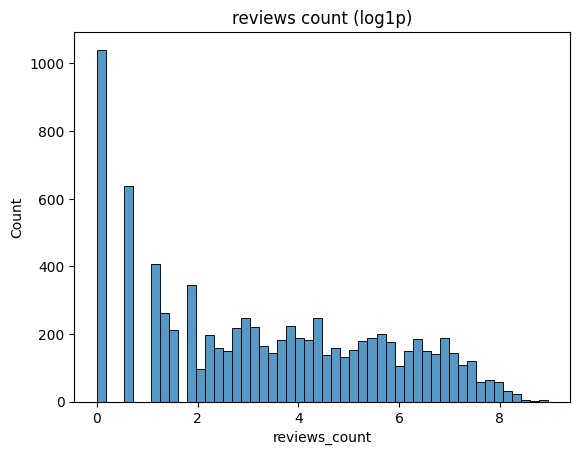

In [44]:
sns.histplot(df["reviews_count"], bins=50)
plt.title("reviews count")
plt.show()

# log1p compresses the large values and clarifies the distribution
sns.histplot(np.log1p(df["reviews_count"]), bins=50)
plt.title("reviews count (log1p)")
plt.show()

**Insight: Reviews count.** The number of reviews is highly right-skewed: many hotels have few reviews and a few have thousands. After `np.log1p` the distribution is approximately normal between 2 and 8.

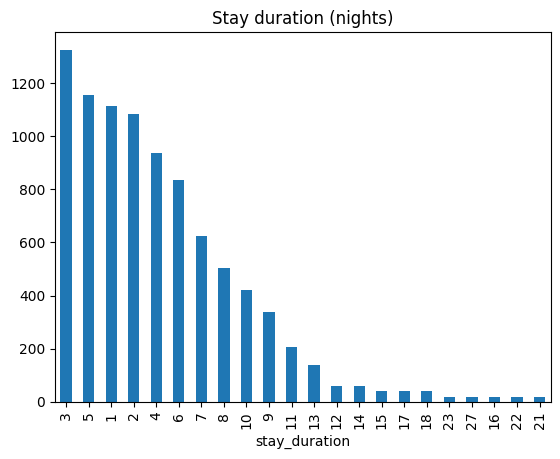

In [45]:
df['stay_duration'].value_counts().plot(kind='bar')
plt.title("Stay duration (nights)")
plt.show()

**Insight: Stay duration.** This shows the stay lengths that exist in the collected data. We note that the majority of stays are between 3 and 8 days.

In [46]:
df['Source'].value_counts()


,count
Source,
Booking.com,6645
TripAdvisor,2382


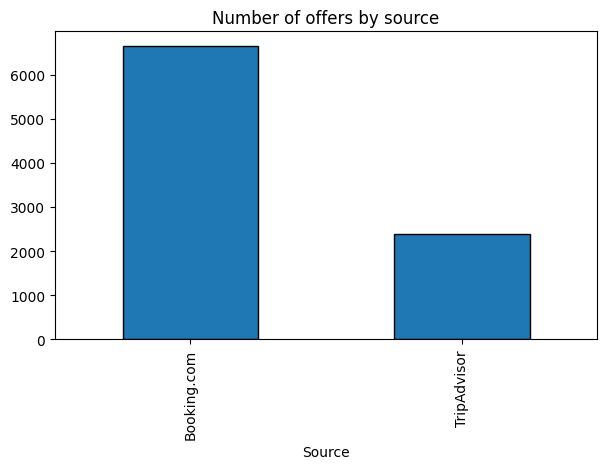

In [47]:
# Number of offers by source
df["Source"].value_counts().plot(kind="bar", figsize=(7, 4), edgecolor="black")
plt.title("Number of offers by source")
plt.show()

**Insight: Source.** Most of the offers come from Booking.com, so the dataset is imbalanced between the two sources.

**Bivariate** **Analysis**

### Location

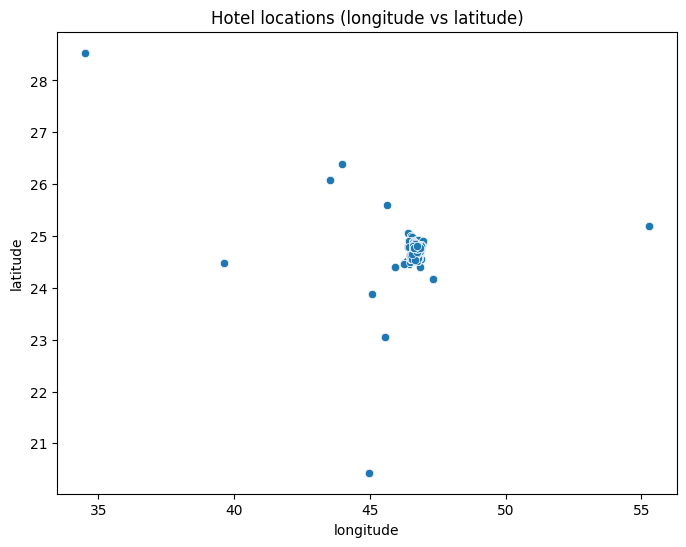

In [48]:
plt.figure(figsize=(8,6))
sns.scatterplot(x="longitude", y="latitude", data=df)
plt.title("Hotel locations (longitude vs latitude)")
plt.show()

**Insight:** the hotels are concentrated in one main area, which is the city of Riyadh, and a few points are far from the main cluster.

### Rating and price per night

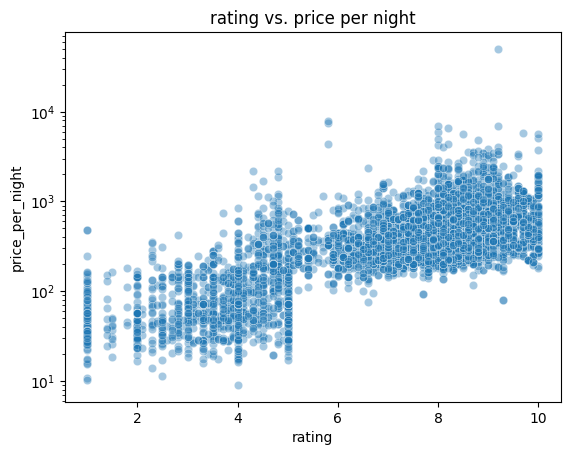

                 price_per_night    rating
price_per_night         1.000000  0.633643
rating                  0.633643  1.000000


In [49]:
# price_per_night and rating
sns.scatterplot(data=df, x="rating", y="price_per_night", alpha=0.4)
plt.yscale("log")
plt.title("rating vs. price per night")
plt.show()

print(df[["price_per_night", "rating"]].corr(method="spearman"))

**Insight: Rating vs. price.** The Spearman correlation is 0.634, a moderately strong positive relationship: hotels with higher ratings tend to have higher nightly prices. Part of this may come from the difference between sources, since Booking.com is more expensive and also uses a different rating scale. Correlation does not imply causation.

### Reviews count and rating

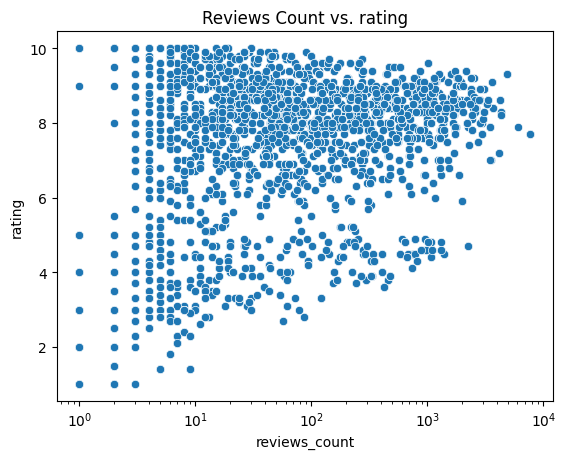

                 rating  reviews_count
rating         1.000000       0.320056
reviews_count  0.320056       1.000000


In [50]:
#rating & reviews_count
sns.scatterplot(data=df, x="reviews_count", y="rating")
plt.xscale("log")
plt.title("Reviews Count vs. rating")
plt.show()
print(df[["rating", "reviews_count"]].corr(method="spearman"))

**Insight: Reviews vs. rating.** The correlation is 0.320, a weak positive relationship. Hotels with more reviews tend to have slightly higher ratings.

### Reviews count and price per night

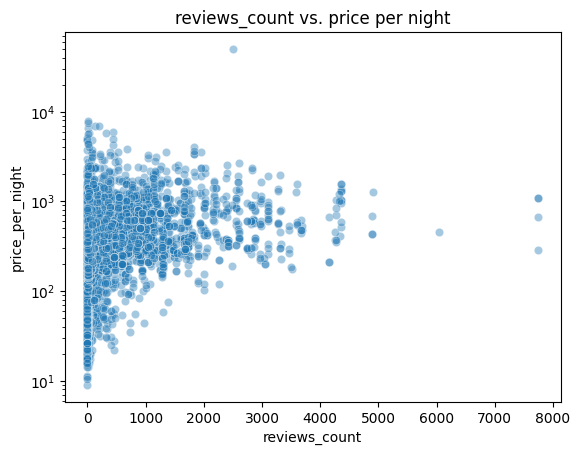

                 price_per_night  reviews_count
price_per_night         1.000000       0.491787
reviews_count           0.491787       1.000000


In [51]:
# price_per_night and reviews_count
sns.scatterplot(data=df, x="reviews_count", y="price_per_night", alpha=0.4)
plt.yscale("log")
plt.title("reviews_count vs. price per night")
plt.show()

print(df[["price_per_night", "reviews_count"]].corr(method="spearman"))

**Insight: Reviews vs. price.** The correlation is 0.492, a moderate positive relationship: higher-priced hotels tend to have more reviews. However, correlation does not imply causation.

### Stay duration and price per night

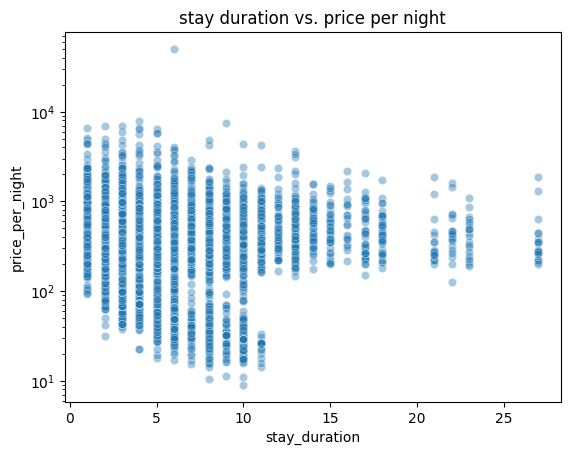

                 stay_duration  price_per_night
stay_duration         1.000000        -0.099511
price_per_night      -0.099511         1.000000


In [52]:
# stay duration & price per night
sns.scatterplot(data=df, x="stay_duration", y="price_per_night", alpha=0.4)
plt.yscale("log")
plt.title("stay duration vs. price per night")
plt.show()
print(df[["stay_duration", "price_per_night"]].corr(method="spearman"))

**Insight: Stay duration vs. price.** The correlation is -0.09, a very weak negative relationship: longer stays are only slightly cheaper per night, so stay duration is not a major factor in the nightly price.

### Source, price and rating

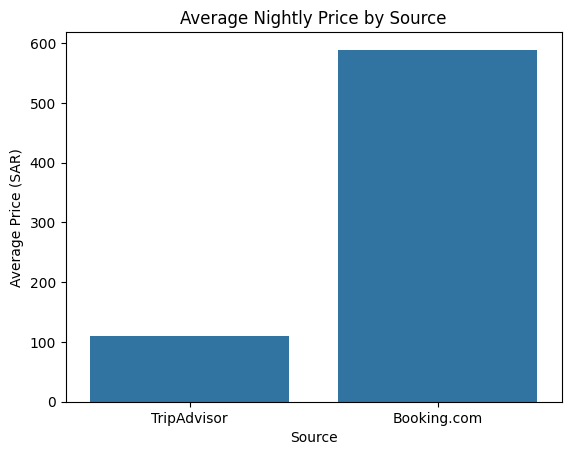

In [53]:
# Compare average nightly price by source
sns.barplot(data=df, x="Source", y="price_per_night", errorbar=None)
plt.title("Average Nightly Price by Source")
plt.ylabel("Average Price (SAR)")
plt.show()

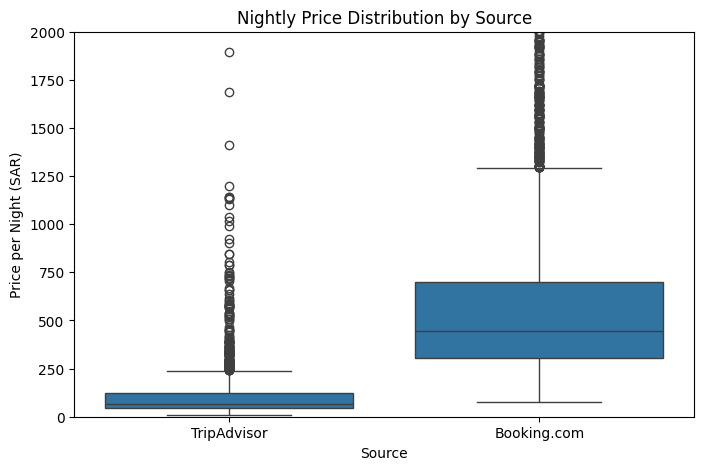

In [54]:
# Compare nightly prices by data source
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Source", y="price_per_night")
plt.ylim(0, 2000)  # limit the axis only so the boxplot is readable (no data is removed)
plt.title("Nightly Price Distribution by Source")
plt.xlabel("Source")
plt.ylabel("Price per Night (SAR)")
plt.show()

**Insight: Price by source.** The average nightly price on Booking.com is higher than on TripAdvisor, even after converting USD to SAR. The extreme values in Booking.com are real because there are luxury hotels with very high prices, so we did not remove them.

In [55]:
# Average rating for each source
df.groupby("Source")["rating"].mean().sort_values()

,rating
Source,
TripAdvisor,3.612760
Booking.com,8.111701


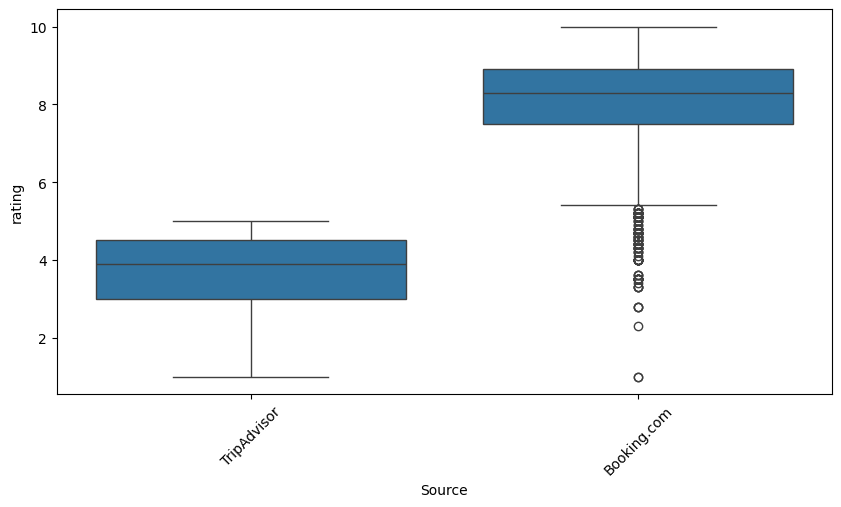

In [56]:
#boxplot
plt.figure(figsize=(10,5))
sns.boxplot(x="Source", y="rating", data=df)
plt.xticks(rotation=45)
plt.show()

**Insight: Rating by source.** The average rating is 8.1 on Booking.com and 3.6 on TripAdvisor. This large difference is mainly because the two platforms use different rating scales, so ratings should not be compared directly between sources. The extreme values in Booking.com are real because a hotel may be rated 1 or higher.

### Check-in date

In [57]:
# Average nightly price for each check-in date
df.groupby("checkin_date")["price_per_night"].mean().sort_values()

,price_per_night
checkin_date,
2026-05-17,225.494747
2026-05-23,322.452916
2026-05-09,352.019651
2026-05-16,358.667273
2026-05-05,375.201396
2026-05-03,375.787829
2026-05-28,385.706197
2026-05-11,389.621433
2026-05-15,391.365835


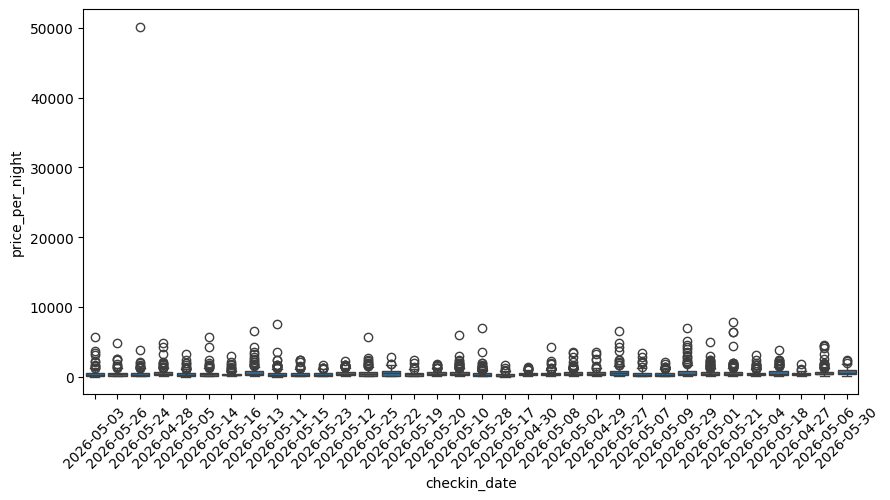

In [58]:
plt.figure(figsize=(10,5))
sns.boxplot(x="checkin_date", y="price_per_night", data=df)
plt.xticks(rotation=45)
plt.show()

**Insight: Check-in date.** The average nightly price changes from one check-in date to another (from about 225 SAR on 17 May to about 689 SAR on 30 May), but there is no single consistent pattern, so we cannot confirm a holiday effect (such as Eid al-Adha) from this data alone.

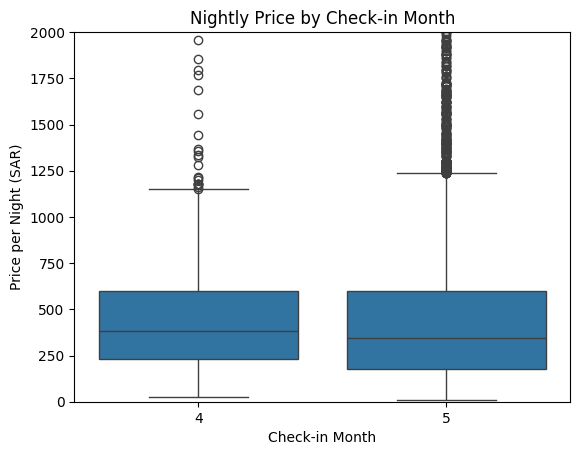

In [59]:
# Extract check-in month
df["checkin_month"] = pd.to_datetime(df["checkin_date"]).dt.month

# Compare nightly prices across check-in months
sns.boxplot(data=df, x="checkin_month", y="price_per_night")
plt.ylim(0, 2000)
plt.title("Nightly Price by Check-in Month")
plt.xlabel("Check-in Month")
plt.ylabel("Price per Night (SAR)")
plt.show()

**Insight: Month.** The data only includes April and May, so the month comparison is limited.

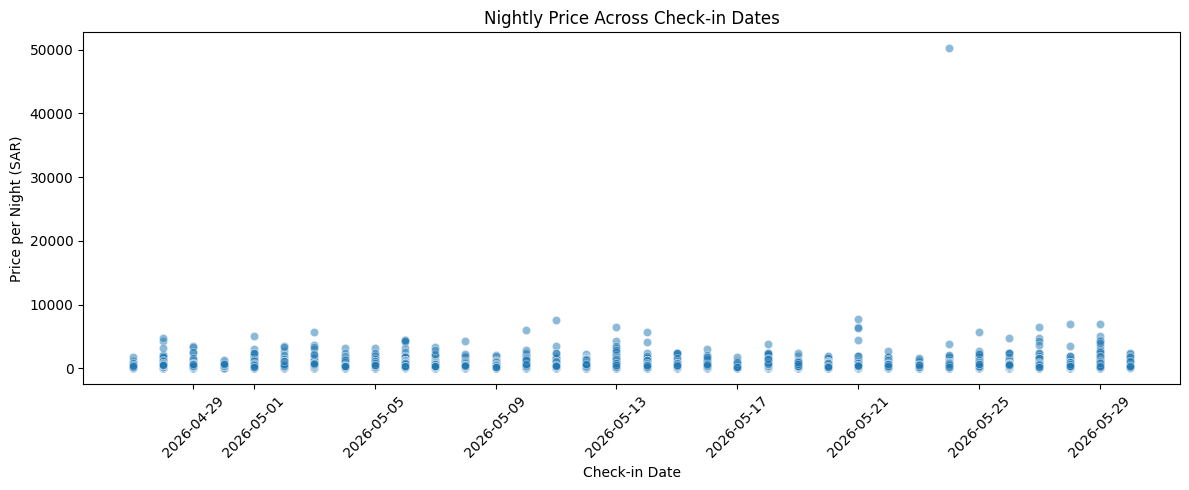

In [60]:
# Convert check-in dates and extract the day
df["checkin_date"] = pd.to_datetime(df["checkin_date"])
df["checkin_day"] = df["checkin_date"].dt.day

# Compare nightly prices by check-in date
plt.figure(figsize=(12, 5))
sns.scatterplot(data=df, x="checkin_date", y="price_per_night", alpha=0.5)

plt.title("Nightly Price Across Check-in Dates")
plt.xlabel("Check-in Date")
plt.ylabel("Price per Night (SAR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:** the scatter plot shows that nightly prices are spread across all check-in dates without a clear trend.

### Correlation between features

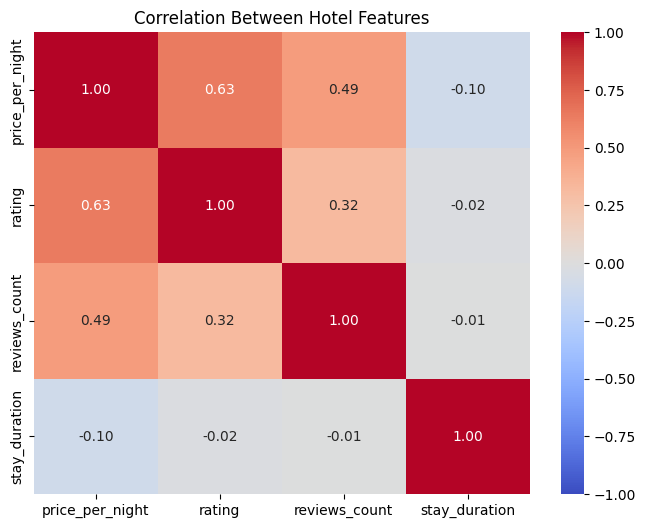

In [61]:
# Select numeric columns for correlation analysis
numeric_cols = [
    "price_per_night",
    "rating",
    "reviews_count",
    "stay_duration"
]

# Calculate correlations
corr = df[numeric_cols].corr(method="spearman")

# Plot the correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Between Hotel Features")
plt.show()

**Insight: Correlation heatmap.** Price per night has its strongest relationships with rating and reviews count, while stay duration has almost no relationship with the other features.

**Multivariate** **Analysis**

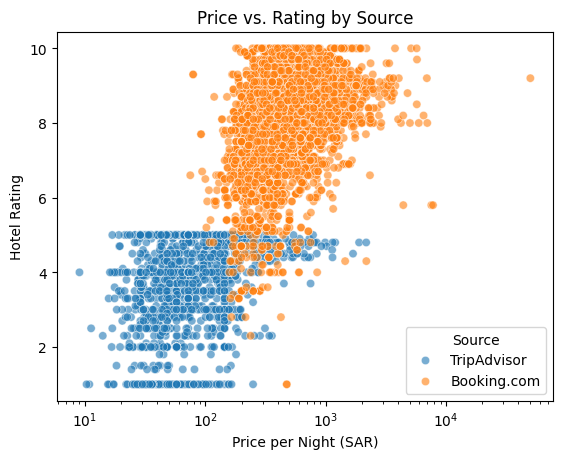

In [62]:
# Compare price-rating relationships across sources
sns.scatterplot(
    data=df,
    x="price_per_night",
    y="rating",
    hue="Source",
    alpha=0.6
)

plt.title("Price vs. Rating by Source")
plt.xlabel("Price per Night (SAR)")
plt.ylabel("Hotel Rating")
plt.xscale("log")
plt.show()

**Insight: Price vs. rating by source.** The two sources form two different groups: Booking.com has higher ratings and higher prices, TripAdvisor has lower ratings and lower prices. This explains part of the positive correlation between price and rating.

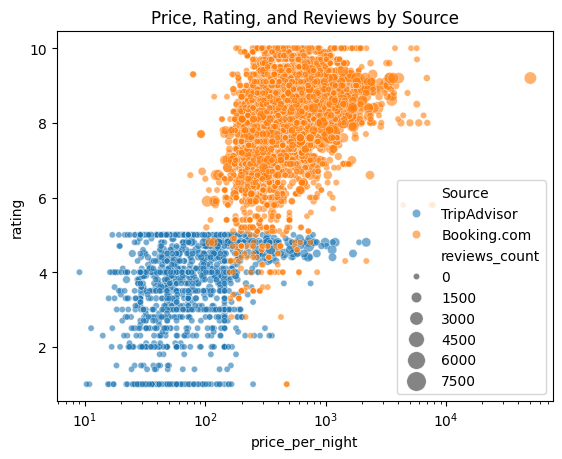

In [63]:
# Visualize three hotel features together
sns.scatterplot(
    data=df,
    x="price_per_night",
    y="rating",
    size="reviews_count",
    hue="Source",
    sizes=(20, 200),
    alpha=0.6
)
plt.xscale("log")
plt.title("Price, Rating, and Reviews by Source")
plt.show()
#The size of the circle indicates the number of reviews.

**Insight: Price, rating and reviews.** The size of the circle represents the number of reviews. Hotels with many reviews are mostly in the middle to high price range, while hotels with very few reviews are spread across all prices.

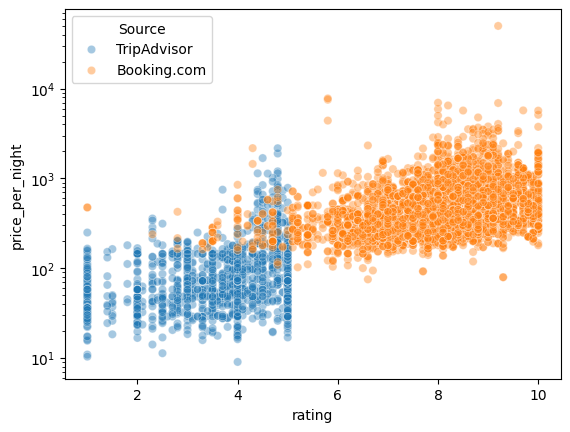

Booking.com 0.3645365279908345
TripAdvisor 0.27624535078144624


In [68]:
sns.scatterplot(data=df, x="rating", y="price_per_night", hue="Source", alpha=0.4)
plt.yscale("log")
plt.show()

for s, g in df.groupby("Source"):
    print(s, g[["price_per_night", "rating"]].corr(method="spearman").iloc[0, 1])

**Insight**: **Rating** **vs** . **price** **by** **source**
The two sources form two separate groups: TripAdvisor ratings are between 1 and 5 with prices mostly below 200 SAR, while Booking.com ratings are between 6 and 10 with much higher prices. This confirms that the two platforms use different rating scales and price levels, so the overall correlation (0.63) is misleading. Inside each source the relationship is weaker (0.36 for Booking.com and 0.28 for TripAdvisor): higher-rated hotels are slightly more expensive, but rating alone does not explain the price.

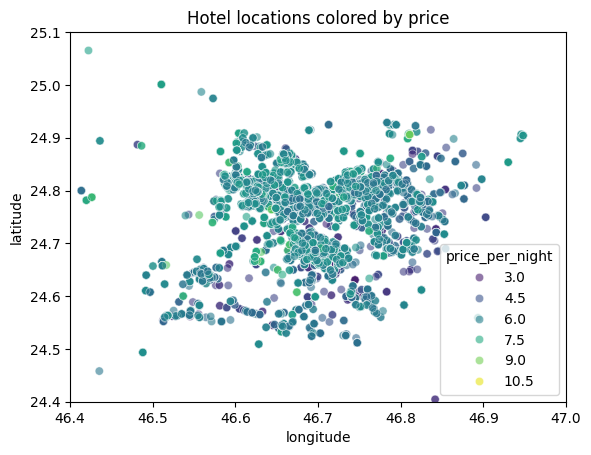

In [78]:
sns.scatterplot(data=df, x="longitude", y="latitude",
                hue=np.log1p(df["price_per_night"]), palette="viridis", alpha=0.6)
plt.xlim(46.4, 47.0)
plt.ylim(24.4, 25.1)
plt.title("Hotel locations colored by price")
plt.show()

**Insight**: **Hotel** **locations** **by** **price**
Hotels are concentrated in the central and northern parts of Riyadh. The more expensive hotels (brighter colors) appear mostly in [area, e.g., around the north / KAFD / Olaya], while cheaper hotels are spread across area. This suggests that location is related to hotel price.

In [70]:
df.nlargest(10, "price_per_night")[["hotel_name", "rating", "price_per_night", "Source"]]

,hotel_name,rating,price_per_night,Source
2929,Narcissus The Royal Hotel,9.2,50205.666667,Booking.com
9433,Riyadh View Chalets شاليهات الرياض فيو,5.8,7797.000000,Booking.com
9209,Riyadh View Chalets شاليهات الرياض فيو,5.8,7549.111111,Booking.com
7972,Amaaria Aquapark resort Villas & Chalet,8.0,6986.250000,Booking.com
8705,The St. Regis Riyadh,9.2,6931.050000,Booking.com
7754,W Riyadh - KAFD,NaN,6520.500000,Booking.com
3632,Portal Chalets With Private Pool - AlQirwan,8.2,6511.185000,Booking.com
7392,W Riyadh - KAFD,NaN,6411.825000,Booking.com
9444,W Riyadh - KAFD,NaN,6384.656250,Booking.com
4765,Holiday Inn Riyadh Olaya by IHG,8.0,5936.070000,Booking.com


**Insight**:**Most** **expensive** **hotels**
All of the 10 most expensive offers come from Booking.com. They include well-known luxury hotels (The St. Regis, W Riyadh - KAFD, Holiday Inn Olaya) and also chalets and resort villas. This supports keeping the high prices, since most of them are real luxury properties. It also shows that price does not depend on rating alone: for example, Riyadh View Chalets has a rating of 5.8 but a very high price, and the three offers of W Riyadh - KAFD have no rating at all.

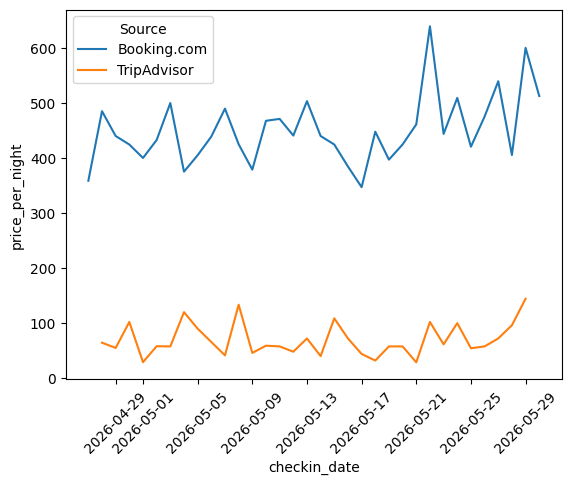

In [76]:
daily = df.groupby(["checkin_date", "Source"])["price_per_night"].median().reset_index()
sns.lineplot(data=daily, x="checkin_date", y="price_per_night", hue="Source")
plt.xticks(rotation=45)
plt.show()

**Insight**: **Median** **price** **by** **check**-**in** **date**
Booking.com median prices are much higher than TripAdvisor at every date (about 350–640 SAR vs. 30–145 SAR). Prices fluctuate from day to day in both sources without a steady trend, but both show higher values at the end of May (around 29 May), and Booking.com has its highest peaks on 22 and 29 May. This may be related to the Eid al-Adha period at the end of May, but the data covers only one month and the peaks are not very large compared to the daily fluctuations, so we cannot confirm a holiday effect.

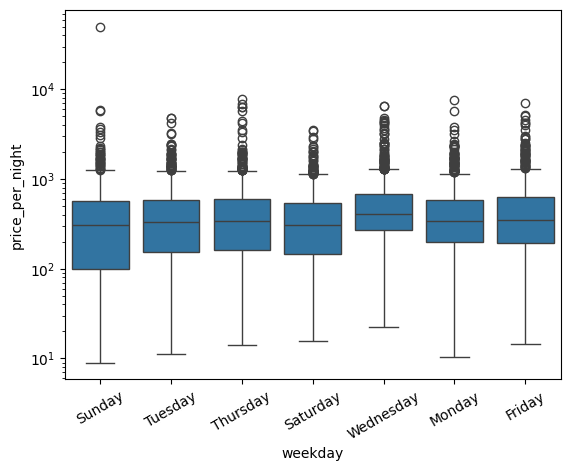

In [77]:
df["weekday"] = df["checkin_date"].dt.day_name()
sns.boxplot(data=df, x="weekday", y="price_per_night")
plt.yscale("log")
plt.xticks(rotation=30)
plt.show()

**Insight**: **Price** **by** **check**-**in** **weekday**
The median nightly price is similar across the days of the week (roughly between 300 and 400 SAR), and the boxes overlap heavily. Wednesday has a slightly higher median, while Saturday and Sunday are slightly lower. There is no clear weekend effect on hotel prices. The very high point on Sunday is the Narcissus hotel outlier.



# Summary & Key Insights

## What is the dataset about?
The dataset contains hotel offers in Riyadh (2026) collected from Booking.com and TripAdvisor. After cleaning, there are 9,027 offers for 2,728 unique hotels, with check-in dates between 27 April and 30 May 2026. Each offer includes the hotel location, rating, number of reviews and the total stay price, which we converted to SAR and divided by the number of nights to get the price per night. These are displayed prices, not confirmed bookings, and the same hotel appears several times with different dates.

## What main questions did we explore?
1. How are nightly prices distributed, and what is a typical price?
2. Are rating and number of reviews related to price?
3. Do stay duration, check-in date and weekday affect the price?
4. How do Booking.com and TripAdvisor differ?
5. Where are the hotels located in Riyadh?

## What insights did we find?

### 1. Price distribution
- **Prices are highly right-skewed.** The median nightly price is about 350 SAR while the mean is about 463 SAR, because a few luxury hotels are very expensive. We used the median and a logarithmic scale (`np.log1p`) to describe and plot prices.
- **Extreme prices are mostly real.** The most expensive offers are all on Booking.com and are luxury hotels (The St. Regis, W Riyadh - KAFD, Holiday Inn Olaya) and chalets or resort villas, so we kept them. One offer (Narcissus The Royal Hotel, about 50,000 SAR per night) is around seven times higher than the second most expensive offer, so it is treated as an extreme case.

### 2. Rating, reviews and price
- **Rating and price** have a moderately strong positive correlation overall (0.63), but this is partly caused by the difference between the two sources. Inside each source the relationship is weaker (0.36 for Booking.com and 0.28 for TripAdvisor), so higher-rated hotels are only slightly more expensive and rating alone is a weak predictor of price.
- **Price does not depend on rating alone.** For example, a chalet property with a rating of 5.8 has a very high price, and some luxury hotels (W Riyadh - KAFD) have no rating at all.
- **Reviews count** is highly right-skewed (many hotels have few reviews and a few have thousands). It has a moderate positive correlation with price (0.49) and a weak one with rating (0.32).

### 3. Stay duration, date and weekday
- **Stay duration** has a very weak negative correlation with nightly price (-0.10), so longer stays are only slightly cheaper per night.
- **Check-in date:** prices fluctuate from day to day without a steady trend, but both sources show higher values at the end of May (around 29 May), and Booking.com peaks on 22 and 29 May. This may be related to Eid al-Adha, but the data covers only one month and the peaks are small compared to the daily fluctuations, so we cannot confirm a holiday effect.
- **Weekday:** median prices are similar across the days of the week (roughly 300–400 SAR) and the boxes overlap heavily. Wednesday is slightly higher and Saturday and Sunday slightly lower, but there is no clear weekend effect.

### 4. Sources
- **Source matters.** Booking.com is much more expensive than TripAdvisor, even after converting USD to SAR (median prices by date are about 350–640 SAR on Booking.com vs. 30–145 SAR on TripAdvisor).
- **The two sources use different rating scales** (Booking.com out of 10, TripAdvisor out of 5), which creates two separate groups in the rating–price plot. Ratings therefore cannot be compared directly between sources, and most offers (about 74%) come from Booking.com, so the data is imbalanced.

### 5. Location
- Hotels are concentrated in one dense area in Riyadh (around longitude 46.7 and latitude 24.7). About ten points have coordinates far from the city (latitude 20–28.5, longitude 34–55), which are probably wrong coordinates.

### Missing data
- Many hotels have no rating because they have no reviews. We kept them as missing instead of inventing values. Missing TripAdvisor prices were filled with the median of their source.

## Limitations
The data covers only about one month, the prices are offers and not real bookings, the same hotels appear on several dates, and missing TripAdvisor prices were filled with the source median. Some coordinates are outside Riyadh. Correlation does not imply causation.

In [80]:
df_clean = df.copy()
df_clean.to_csv("Riyadh_Hotels_clean.csv", index=False)
